# 2026-09-04 DNA Quantification — Standard Curve (Portelite BDR / Qubit)

Same assay/method as [`0622_quantification.ipynb`](0622_quantification.ipynb),
[`0629_quantification.ipynb`](0629_quantification.ipynb) and
[`0710_quantification.ipynb`](0710_quantification.ipynb): a fresh standard series is read this
session, fit by **linear regression of RFU vs. concentration (ng/µL)**, then each sample reading
is inverted on the fitted line.

**Kit:** Portelite™ Fluorimetric DNA Quantitation Kit, Broad Dynamic Range (AAT Bioquest 17665),
Ex/Em 480/530 nm, green channel, Qubit 4 in raw-RFU mode.

**Samples:** five — `e1`, `e40`, `e281`, `CDS_11`, `CDS_12`.

**Three sections:** (1) build the standard curve (**two fits** — see below), (2) convert each
reading to ng/µL, (3) DNA mass per tube.

## Session notes (2026-09-04) — read before trusting any number

- **5 µL per tube this session, not the team-default 10 µL — standards *and* samples alike**
  (user-confirmed 2026-09-04). So `STD_VOL_uL = SAMPLE_VOL_uL = 5.0` and **`VOL_CORRECTION = 1`:
  no volume correction is applied, and none is needed.**
  Why it would have mattered: the Portelite readout is fluorescence from the dye bound to the DNA
  **actually in the tube**, i.e. it scales with **mass** (conc × load volume), not with
  concentration. The curve maps `RFU → ng/µL` only under the load volume the standards were run
  at. Halving just the sample load would halve its RFU at unchanged concentration, and the curve
  would read it back 2× too low — hence the correction factor `STD_VOL_uL / SAMPLE_VOL_uL`. Here
  both sides moved together, so the factor is exactly 1 and the curve is self-consistent.
  What the 5 µL load *does* cost is **signal**: every RFU this session is ~half what the same
  sample would have given at 10 µL, which pushes these already-low samples further down toward the
  blank. (It is not visible in the slope — the session-to-session slope spans ~9× across
  0605/0608/0622/0710 at the same nominal 10 µL, so dye lot / working-solution age dominates. Only
  the bench record settles the volume, and it has.)
- **⚠ Every sample sits at the very bottom of the curve, bracketed by S1 and S3.** The samples
  span 274.75–339.87 RFU; S0 (blank) is 143.23, S1 is 238.53, S3 is 439.12 — so all five land in
  the narrow **S1–S3 window**, with only one standard (S1) beneath them. This is the mirror image
  of 0710 (where everything was extrapolated *above* the top standard); the caution here is
  **low-end resolution**, not extrapolation. On the GLOBAL fit all five drop below 1 ng/µL.
- **Two fits are reported, because the fit window decides the answer.** The full 6-point fit is
  dominated by the S100 point (leverage) and carries a **+127 RFU intercept**, which eats most of
  the sample signal; the low-end **S0/S1/S3** fit has an essentially zero intercept
  (−1.43) and R² = 0.99984. For `e40` the two disagree **~22×** (0.06 vs 1.34 ng/µL) — the
  difference between "failed prep, no DNA" and "low but real". **The low-end fit is the one to
  quote — confirmed by Alex 2026-09-04** (the samples are bracketed by S1–S3; the global fit is
  extrapolating a high-concentration line down into a region it does not describe). Both are
  computed and plotted below — preserve-all-versions.
- **Kit sensitivity floor is 0.2 ng/µL.** Even on the low-end fit all five are ≈1.3–2.0 ng/µL,
  i.e. above the floor but in the bottom few percent of the kit's 0.2–100 ng/µL range. These are
  **low-yield preps**.
- **Sample identity is not yet resolved.** `CDS_11` / `CDS_12` are read as the phage 9-2-1 Φ8
  **`CDS_0011`** (tail-spike β-helix) and **`CDS_0012`** (GH5) constructs. `e1` / `e40` / `e281`
  appear nowhere else in the repo and are transcribed exactly as written on the page.
  `[Question: what are e1 / e40 / e281?]`
- **`e1` last digit is ambiguous** on the page (`339.8` with a digit overwritten; read here as
  **339.87**). Immaterial — 339.8 vs 339.87 moves the concentration by <0.001 ng/µL.
- **Volume budget (user-reported 2026-09-04):** ~**45 µL** left per tube at the time of this read,
  then **5 µL per sample** drawn for the **transformation**, leaving **~40 µL** per tube now.
  Section 3 reports DNA mass at all three stages. Nothing is inferred here — 0710 guessed 90 µL
  from the bacterial-extract records and its own correction note later retracted the derived masses.
- **`DILUTION_FACTOR = 1`** (samples read undiluted) — assumed, still unconfirmed.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- Tunable assay parameters -------------------------------------------------
DILUTION_FACTOR = 1          # assumed undiluted this session (UNCONFIRMED)

# Load volumes. 5 uL per tube for BOTH standards and samples this session (user-confirmed
# 2026-09-04), vs the team-default 10 uL. The Portelite signal scales with DNA MASS in the tube
# (conc x load volume), so a curve built at one load volume only reads back samples run at the
# same one; the correction factor below is STD_VOL_uL / SAMPLE_VOL_uL. Both are 5 uL here, so it
# is exactly 1 and no correction is applied. (The 5 uL load does halve the signal vs 10 uL.)
SAMPLE_VOL_uL = 5.0
STD_VOL_uL    = 5.0
VOL_CORRECTION = STD_VOL_uL / SAMPLE_VOL_uL   # = 1.0 under the assumption above

# Per-tube volume budget (uL), user-reported 2026-09-04:
#   ~45 uL left in each tube at the time of this quantification, then transformation drew 5 uL
#   per sample off that -> ~40 uL is what is physically left now.
VOL_AT_QUANT_uL        = 45.0   # remaining per tube when the Qubit read was taken
VOL_USED_TRANSFORM_uL  = 5.0    # drawn per sample for the transformation
VOL_REMAINING_uL       = VOL_AT_QUANT_uL - VOL_USED_TRANSFORM_uL   # = 40.0 uL left now

DATE = '2026-09-04'
OUTPUT_DIR = 'output/0904_quantification'   # figures saved here, named by date + content
os.makedirs(OUTPUT_DIR, exist_ok=True)
# -------------------------------------------------------------------------------
print(f'sample vol {SAMPLE_VOL_uL} uL / standard vol {STD_VOL_uL} uL '
      f'-> volume correction x{VOL_CORRECTION:g}')

sample vol 5.0 uL / standard vol 5.0 uL -> volume correction x1


## Section 1 — Build the standard curve

A full 6-point series (S0–S100) was read this session, so the **S0 blank is subtracted** from every
standard and every sample before fitting.

Two linear fits are built on the blank-subtracted points:

- **GLOBAL** — all six points (S0…S100). Anchored by S100; large positive intercept.
- **LOWEND** — **S0, S1, S3 only**, the window that actually brackets this session's samples.

Both are reported. Section 2 quotes **LOWEND** as primary.

In [2]:
# Standards (ng/uL, raw green-channel RFU) -- read 2026-09-04, 5 uL per tube.
standards = pd.DataFrame({
    'standard':   ['Std 0 (blank)', 'Std 1', 'Std 3', 'Std 10', 'Std 30', 'Std 100'],
    'conc_ng_uL': [0.0, 1.0, 3.0, 10.0, 30.0, 100.0],
    'rfu':        [143.23, 238.53, 439.12, 917.66, 2924.99, 7346.87],
})

BLANK_RFU = standards.loc[standards['conc_ng_uL'] == 0, 'rfu'].iloc[0]
standards['rfu_corrected'] = standards['rfu'] - BLANK_RFU


def fit_curve(df, label):
    """Linear-fit an already blank-subtracted standards table. Returns fit params + the subset."""
    slope, intercept = np.polyfit(df['conc_ng_uL'], df['rfu_corrected'], 1)
    fit = slope * df['conc_ng_uL'] + intercept
    ss_res = np.sum((df['rfu_corrected'] - fit) ** 2)
    ss_tot = np.sum((df['rfu_corrected'] - df['rfu_corrected'].mean()) ** 2)
    return {'label': label, 'df': df, 'slope': slope, 'intercept': intercept,
            'r2': 1 - ss_res / ss_tot,
            'min_conc': df['conc_ng_uL'].max() and df.loc[df['conc_ng_uL'] > 0, 'conc_ng_uL'].min(),
            'max_conc': df['conc_ng_uL'].max()}


GLOBAL = fit_curve(standards, 'GLOBAL (S0-S100)')
LOWEND = fit_curve(standards[standards['conc_ng_uL'] <= 3.0], 'LOWEND (S0/S1/S3)')

MAX_STD_CONC = standards['conc_ng_uL'].max()     # 100 ng/uL -> above this = extrapolated
MIN_STD_CONC = 1.0                               # S1 -> below this = below the lowest non-zero std
KIT_FLOOR_NG_UL = 0.2                            # Portelite BDR stated sensitivity floor

print(f'Blank (Std 0) RFU : {BLANK_RFU:.2f}')
for c in (GLOBAL, LOWEND):
    print(f"{c['label']:20s} slope={c['slope']:9.4f} RFU/(ng/uL)  "
          f"intercept={c['intercept']:9.4f} RFU  R^2={c['r2']:.6f}  "
          f"fit window 0-{c['max_conc']:.0f} ng/uL")
print(f'\nTop standard      : {MAX_STD_CONC:.0f} ng/uL (above -> extrapolated)')
print(f'Lowest non-zero   : {MIN_STD_CONC:.0f} ng/uL (below -> under the lowest standard)')
standards

Blank (Std 0) RFU : 143.23
GLOBAL (S0-S100)     slope=  72.1366 RFU/(ng/uL)  intercept= 127.2258 RFU  R^2=0.992572  fit window 0-100 ng/uL
LOWEND (S0/S1/S3)    slope=  98.8679 RFU/(ng/uL)  intercept=  -1.4271 RFU  R^2=0.999844  fit window 0-3 ng/uL

Top standard      : 100 ng/uL (above -> extrapolated)
Lowest non-zero   : 1 ng/uL (below -> under the lowest standard)


,standard,conc_ng_uL,rfu,rfu_corrected
0,Std 0 (blank),0.0,143.23,0.00
1,Std 1,1.0,238.53,95.30
2,Std 3,3.0,439.12,295.89
3,Std 10,10.0,917.66,774.43
4,Std 30,30.0,2924.99,2781.76
5,Std 100,100.0,7346.87,7203.64


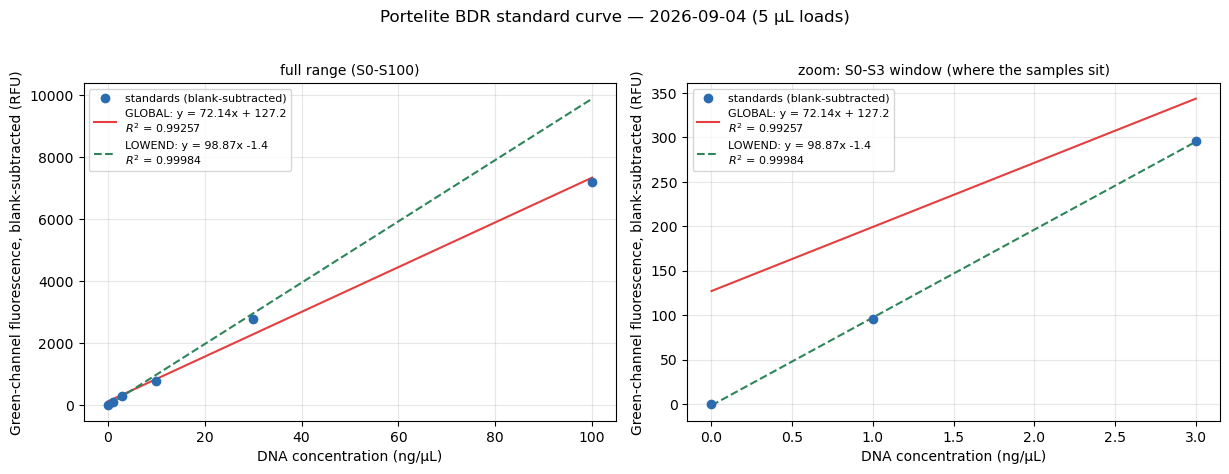

In [3]:
# Conversion helpers: invert a fitted line, apply dilution factor and the load-volume correction.
def make_converter(curve):
    """Raw green-channel RFU -> DNA concentration (ng/uL) in the original tube, for this curve."""
    def conv(rfu):
        return ((np.asarray(rfu, dtype=float) - BLANK_RFU - curve['intercept'])
                / curve['slope'] * DILUTION_FACTOR * VOL_CORRECTION)
    return conv

rfu_to_conc_global = make_converter(GLOBAL)
rfu_to_conc_lowend = make_converter(LOWEND)
rfu_to_conc = rfu_to_conc_lowend      # PRIMARY: samples sit inside the S0-S3 window

# Plot both fits: full range (left) and zoomed on the S0-S3 window where the samples live (right).
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6))
for ax, xmax, title in [
        (axes[0], MAX_STD_CONC, 'full range (S0-S100)'),
        (axes[1], 3.0,          'zoom: S0-S3 window (where the samples sit)')]:
    sub = standards[standards['conc_ng_uL'] <= xmax]
    ax.scatter(sub['conc_ng_uL'], sub['rfu_corrected'], color='#2b6cb0', zorder=4,
               label='standards (blank-subtracted)')
    xline = np.linspace(0, xmax, 100)
    ax.plot(xline, GLOBAL['slope'] * xline + GLOBAL['intercept'], color='#e53e3e', lw=1.5,
            label=f"GLOBAL: y = {GLOBAL['slope']:.2f}x + {GLOBAL['intercept']:.1f}\n"
                  f"$R^2$ = {GLOBAL['r2']:.5f}")
    ax.plot(xline, LOWEND['slope'] * xline + LOWEND['intercept'], color='#2f855a', lw=1.5, ls='--',
            label=f"LOWEND: y = {LOWEND['slope']:.2f}x {LOWEND['intercept']:+.1f}\n"
                  f"$R^2$ = {LOWEND['r2']:.5f}")
    ax.set_xlabel('DNA concentration (ng/µL)')
    ax.set_ylabel('Green-channel fluorescence, blank-subtracted (RFU)')
    ax.set_title(title, fontsize=10)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle('Portelite BDR standard curve — 2026-09-04 (5 µL loads)', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 2 — Sample DNA concentrations

Convert each raw reading to ng/µL on **both** fits. `conc_ng_uL` is the **LOWEND** value (primary);
`conc_ng_uL_global` is kept alongside so the fit-window sensitivity is visible.

`below_lowest_std = True` flags any sample under the S1 (1 ng/µL) standard — none are, on the
LOWEND fit; all five are, on the GLOBAL fit. `below_kit_floor = True` flags anything under the
kit's stated 0.2 ng/µL sensitivity floor.

In [4]:
# Raw green-channel readings, 2026-09-04, 5 uL per sample.
# CDS_11 / CDS_12 read as the 9-2-1 Phi8 CDS_0011 (tail spike) / CDS_0012 (GH5) constructs.
# e1 / e40 / e281 are transcribed as written on the bench page -- identity [TBD].
# e1: last digit overwritten on the page (339.8 / 339.87); read as 339.87, immaterial either way.
samples = pd.DataFrame([
    ('e1',     339.87),
    ('e40',    274.75),
    ('e281',   325.10),
    ('CDS_11', 337.19),
    ('CDS_12', 312.05),
], columns=['sample', 'rfu'])

samples['conc_ng_uL']        = rfu_to_conc_lowend(samples['rfu'])   # primary
samples['conc_ng_uL_global'] = rfu_to_conc_global(samples['rfu'])   # for comparison
samples['fit_ratio']         = samples['conc_ng_uL'] / samples['conc_ng_uL_global']
samples['extrapolated']      = samples['conc_ng_uL'] > MAX_STD_CONC
samples['below_lowest_std']  = samples['conc_ng_uL'] < MIN_STD_CONC
samples['below_kit_floor']   = samples['conc_ng_uL'] < KIT_FLOOR_NG_UL

with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples[['sample', 'rfu', 'conc_ng_uL', 'conc_ng_uL_global', 'fit_ratio',
                   'below_lowest_std', 'below_kit_floor']].to_string(index=False))

print(f"\nS0 blank = {BLANK_RFU:.2f} RFU, S1 = {standards.loc[1, 'rfu']:.2f} RFU, "
      f"S3 = {standards.loc[2, 'rfu']:.2f} RFU")
print(f"Sample RFU range: {samples['rfu'].min():.2f} - {samples['rfu'].max():.2f} "
      f"-> all {len(samples)} samples fall inside the S0-S3 window.")
print(f"Below the S1 (1 ng/uL) standard, LOWEND fit : "
      f"{int(samples['below_lowest_std'].sum())} of {len(samples)}")
print(f"Below the S1 (1 ng/uL) standard, GLOBAL fit : "
      f"{int((samples['conc_ng_uL_global'] < MIN_STD_CONC).sum())} of {len(samples)}")
print("NOTE: GLOBAL and LOWEND disagree by up to "
      f"{samples['fit_ratio'].max():.0f}x (worst: "
      f"{samples.loc[samples['fit_ratio'].idxmax(), 'sample']}). The GLOBAL fit's +"
      f"{GLOBAL['intercept']:.0f} RFU intercept is S100 leverage and swallows most of the sample "
      "signal; LOWEND is quoted.")

sample     rfu  conc_ng_uL  conc_ng_uL_global  fit_ratio  below_lowest_std  below_kit_floor
    e1 339.870       2.003              0.962      2.082             False            False
   e40 274.750       1.345              0.060     22.589             False            False
  e281 325.100       1.854              0.758      2.447             False            False
CDS_11 337.190       1.976              0.925      2.136             False            False
CDS_12 312.050       1.722              0.577      2.986             False            False

S0 blank = 143.23 RFU, S1 = 238.53 RFU, S3 = 439.12 RFU
Sample RFU range: 274.75 - 339.87 -> all 5 samples fall inside the S0-S3 window.
Below the S1 (1 ng/uL) standard, LOWEND fit : 0 of 5
Below the S1 (1 ng/uL) standard, GLOBAL fit : 5 of 5
NOTE: GLOBAL and LOWEND disagree by up to 23x (worst: e40). The GLOBAL fit's +127 RFU intercept is S100 leverage and swallows most of the sample signal; LOWEND is quoted.


### Section 2 plots — concentration per sample, and samples on the curve

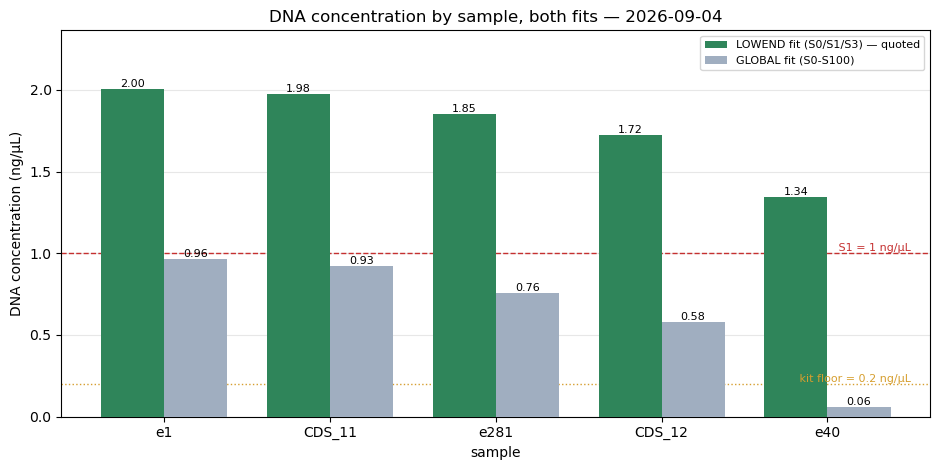

In [5]:
# Bar chart: DNA concentration per sample, both fits side by side.
df = samples.sort_values('conc_ng_uL', ascending=False).reset_index(drop=True)
x = np.arange(len(df)); w = 0.38

fig, ax = plt.subplots(figsize=(9.5, 4.8))
b1 = ax.bar(x - w/2, df['conc_ng_uL'],        w, color='#2f855a', zorder=3, label='LOWEND fit (S0/S1/S3) — quoted')
b2 = ax.bar(x + w/2, df['conc_ng_uL_global'], w, color='#a0aec0', zorder=3, label='GLOBAL fit (S0-S100)')
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.2f}',
                ha='center', va='bottom', fontsize=8)
ax.axhline(MIN_STD_CONC, color='#c53030', ls='--', lw=1, zorder=2)
ax.text(len(df) - 0.5, MIN_STD_CONC, ' S1 = 1 ng/µL', color='#c53030', fontsize=8, va='bottom', ha='right')
ax.axhline(KIT_FLOOR_NG_UL, color='#d69e2e', ls=':', lw=1, zorder=2)
ax.text(len(df) - 0.5, KIT_FLOOR_NG_UL, ' kit floor = 0.2 ng/µL', color='#d69e2e', fontsize=8,
        va='bottom', ha='right')
ax.set_xticks(x); ax.set_xticklabels(df['sample'])
ax.set_ylabel('DNA concentration (ng/µL)')
ax.set_xlabel('sample')
ax.set_title('DNA concentration by sample, both fits — 2026-09-04')
ax.margins(y=0.18); ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_concentration-by-sample.png'),
            dpi=150, bbox_inches='tight')
plt.show()

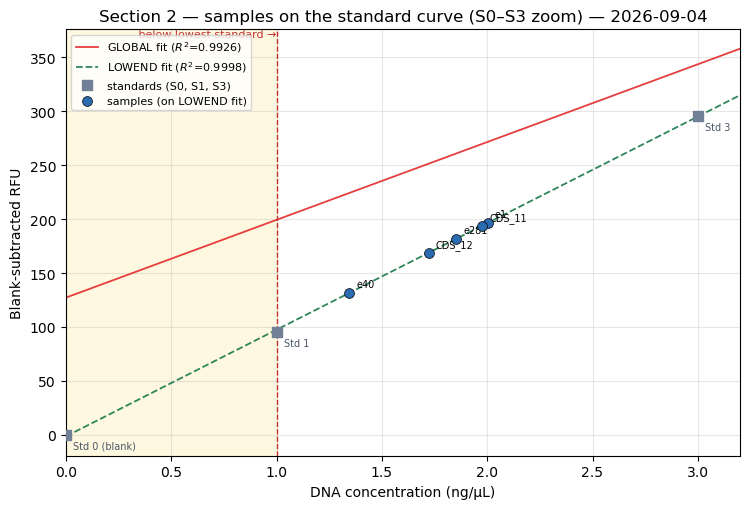

In [6]:
# Place each sample on the standard curve, zoomed to the S0-S3 window it actually occupies.
fig, ax = plt.subplots(figsize=(7.6, 5.2))
xmax = 3.2
xs = np.linspace(0, xmax, 100)
ax.plot(xs, GLOBAL['slope'] * xs + GLOBAL['intercept'], color='#e53e3e', lw=1.3, zorder=2,
        label=f"GLOBAL fit ($R^2$={GLOBAL['r2']:.4f})")
ax.plot(xs, LOWEND['slope'] * xs + LOWEND['intercept'], color='#2f855a', lw=1.3, ls='--', zorder=2,
        label=f"LOWEND fit ($R^2$={LOWEND['r2']:.4f})")
sub = standards[standards['conc_ng_uL'] <= xmax]
ax.scatter(sub['conc_ng_uL'], sub['rfu_corrected'], color='#718096', marker='s', s=45, zorder=3,
           label='standards (S0, S1, S3)')
for _, r in sub.iterrows():
    ax.annotate(r['standard'], (r['conc_ng_uL'], r['rfu_corrected']),
                textcoords='offset points', xytext=(5, -10), fontsize=7, color='#4a5568')
ax.scatter(samples['conc_ng_uL'], samples['rfu'] - BLANK_RFU, color='#2b6cb0', s=50, zorder=4,
           edgecolor='black', linewidth=0.5, label='samples (on LOWEND fit)')
for _, r in samples.iterrows():
    ax.annotate(r['sample'], (r['conc_ng_uL'], r['rfu'] - BLANK_RFU),
                textcoords='offset points', xytext=(5, 4), fontsize=7)
ax.axvspan(0, MIN_STD_CONC, color='#fef3c7', alpha=0.55, zorder=1)
ax.axvline(MIN_STD_CONC, color='#c53030', ls='--', lw=1, zorder=2)
ax.text(MIN_STD_CONC, ax.get_ylim()[1], ' below lowest standard →', color='#c53030',
        fontsize=8, va='top', ha='right')
ax.set_xlim(0, xmax)
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Blank-subtracted RFU')
ax.set_title('Section 2 — samples on the standard curve (S0–S3 zoom) — 2026-09-04')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_samples-on-standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — DNA mass: at the read, into the transformation, and left now

`mass = concentration (ng/µL) × volume (µL)`. Reported in **ng** (µg alongside) — every tube here
holds well under 0.1 µg, so ng is the readable unit.

Volume budget per tube, **user-reported 2026-09-04**:

| stage | volume | what it is |
|---|---:|---|
| `VOL_AT_QUANT_uL` | **45 µL** | left in the tube when this Qubit read was taken |
| `VOL_USED_TRANSFORM_uL` | **5 µL** | drawn per sample for the transformation |
| `VOL_REMAINING_uL` | **40 µL** | physically left now |

Concentrations are the **LOWEND (S0/S1/S3) fit** — the primary, per Alex 2026-09-04. GLOBAL-fit
masses are shown in a second column only to size the fit-choice risk; they are **not** the numbers
to use.

Each sample is its own tube, so masses are **additive** across the five.

In [7]:
# Volume budget per tube (see top cell): 45 uL at the read -> 5 uL to transformation -> 40 uL left.
samples['vol_at_quant_uL']  = VOL_AT_QUANT_uL
samples['vol_transform_uL'] = VOL_USED_TRANSFORM_uL
samples['remaining_vol_uL'] = VOL_REMAINING_uL

# Masses in ng, on the LOWEND (primary) fit.
samples['mass_at_quant_ng']  = samples['conc_ng_uL'] * VOL_AT_QUANT_uL
samples['mass_transform_ng'] = samples['conc_ng_uL'] * VOL_USED_TRANSFORM_uL  # DNA into the transformation
samples['mass_remaining_ng'] = samples['conc_ng_uL'] * VOL_REMAINING_uL       # DNA left in the tube now
samples['mass_remaining_ug'] = samples['mass_remaining_ng'] / 1000.0

# Same thing on the GLOBAL fit, to size the fit-choice risk (NOT the quoted numbers).
samples['mass_remaining_ng_global'] = samples['conc_ng_uL_global'] * VOL_REMAINING_uL

cols = ['sample', 'conc_ng_uL', 'mass_at_quant_ng', 'mass_transform_ng',
        'mass_remaining_ng', 'mass_remaining_ug', 'mass_remaining_ng_global']
print(f'Volume budget per tube: {VOL_AT_QUANT_uL:.0f} uL at the read '
      f'- {VOL_USED_TRANSFORM_uL:.0f} uL to transformation '
      f'= {VOL_REMAINING_uL:.0f} uL left now\n')
with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples[cols].to_string(index=False))

print(f"\nDNA into the transformation: "
      f"{samples['mass_transform_ng'].min():.1f} - {samples['mass_transform_ng'].max():.1f} ng "
      f"per sample (5 uL each).")
print(f"DNA left across all {len(samples)} tubes (at {VOL_REMAINING_uL:.0f} uL each): "
      f"{samples['mass_remaining_ng'].sum():,.1f} ng = "
      f"{samples['mass_remaining_ng'].sum() / 1000:,.3f} ug")
print(f"  (same total on the GLOBAL fit, for contrast: "
      f"{samples['mass_remaining_ng_global'].sum():,.1f} ng)")
print(f"\nMean concentration (LOWEND fit): {samples['conc_ng_uL'].mean():,.3f} ng/uL  "
      f"(range {samples['conc_ng_uL'].min():,.3f} - {samples['conc_ng_uL'].max():,.3f})")

out_csv = os.path.join(OUTPUT_DIR, f'{DATE}_quantification.csv')
samples.to_csv(out_csv, index=False)
print(f'saved -> {out_csv}')

Volume budget per tube: 45 uL at the read - 5 uL to transformation = 40 uL left now

sample  conc_ng_uL  mass_at_quant_ng  mass_transform_ng  mass_remaining_ng  mass_remaining_ug  mass_remaining_ng_global
    e1       2.003            90.151             10.017             80.134              0.080                    38.490
   e40       1.345            60.511              6.723             53.788              0.054                     2.381
  e281       1.854            83.428              9.270             74.158              0.074                    30.300
CDS_11       1.976            88.931              9.881             79.050              0.079                    37.004
CDS_12       1.722            77.488              8.610             68.879              0.069                    23.064

DNA into the transformation: 6.7 - 10.0 ng per sample (5 uL each).
DNA left across all 5 tubes (at 40 uL each): 356.0 ng = 0.356 ug
  (same total on the GLOBAL fit, for contrast: 131.2 ng)

Mean

## Readout

- **Curve:** full 6-point S0–S100 series read at 5 µL. Two fits on the blank-subtracted points
  (blank = 143.23 RFU):
  - **GLOBAL** `RFU = 72.14·conc + 127.23`, R² = 0.99257 — the intercept is **S100 leverage**, and
    at these signal levels it eats most of the sample RFU.
  - **LOWEND (S0/S1/S3)** `RFU = 98.87·conc − 1.43`, R² = 0.99984 — near-zero intercept, and it is
    the window that actually brackets every sample. **This is the fit quoted below.**
- **⚠ All five samples sit in the S1–S3 window**, with a single standard (S1) beneath them.
  Sample RFUs are 274.75–339.87 against S0 = 143.23, S1 = 238.53, S3 = 439.12.
  Concentrations (**LOWEND fit**):

  | sample | RFU | LOWEND ng/µL | GLOBAL ng/µL |
  |---|---:|---:|---:|
  | `e1`     | 339.87 | **2.00** | 0.96 |
  | `CDS_11` | 337.19 | **1.98** | 0.93 |
  | `e281`   | 325.10 | **1.85** | 0.76 |
  | `CDS_12` | 312.05 | **1.72** | 0.58 |
  | `e40`    | 274.75 | **1.34** | 0.06 |

  All are above the kit's 0.2 ng/µL floor but sit in the bottom ~2 % of its 0.2–100 ng/µL range —
  **low-yield preps across the board**, tightly clustered (1.34–2.00 ng/µL, 1.5× spread).
- **The fit window decides the answer, most brutally for `e40`:** 1.34 ng/µL (LOWEND) vs
  0.06 ng/µL (GLOBAL) — a **23×** disagreement, i.e. "low but real" vs "essentially nothing".
  Every sample shifts 2–3× between the two fits, and the GLOBAL fit alone would put all five below
  the S1 standard. The LOWEND reading is the defensible one; do not quote the GLOBAL number.
- **Load volume: settled.** Standards and samples were **both 5 µL** (user-confirmed 2026-09-04),
  so `VOL_CORRECTION = 1` — the curve and the samples are on the same mass basis and the ng/µL above
  need no scaling. The 5 µL load does halve the available signal versus the usual 10 µL, which is
  part of why everything sits so close to the blank.
- **One assumption still open:** **no pre-dilution** (`DILUTION_FACTOR = 1`), unconfirmed.
- **Mass per tube (LOWEND fit; 45 µL at the read → 5 µL to transformation → 40 µL left):**

  | sample | at the read (45 µL) | into transformation (5 µL) | **left now (40 µL)** |
  |---|---:|---:|---:|
  | `e1`     | 90.2 ng | 10.0 ng | **80.1 ng** |
  | `CDS_11` | 88.9 ng |  9.9 ng | **79.0 ng** |
  | `e281`   | 83.4 ng |  9.3 ng | **74.2 ng** |
  | `CDS_12` | 77.5 ng |  8.6 ng | **68.9 ng** |
  | `e40`    | 60.5 ng |  6.7 ng | **53.8 ng** |

  **Total left across the five tubes: ≈ 356 ng (0.36 µg).** Each tube is its own extract, so these
  are additive. The transformation received **6.7–10.0 ng per sample** — inside the 1–100 ng window
  a chemical/electro transformation wants, so the low concentration did **not** starve that step.
  What it does rule out is anything mass-hungry downstream: at ≈54–80 ng per tube there is not
  enough for a sequencing submission without a re-prep or a concentration step. (On the GLOBAL fit
  the same five tubes would total only ≈132 ng — another reason the fit choice is not cosmetic.)
- **Next at the bench:** these concentrations are low enough that anything downstream needing mass
  (sequencing submission, cloning) will likely need a **re-prep or a concentration step** rather
  than a re-read — a re-read would land in the same S0–S3 window. If precision at this level is
  what's wanted, read against the **kit-recommended 7-point series** (30/10/3/1/0.3/0.1/0 ng/µL),
  which puts real standards underneath these samples instead of one point at 1 ng/µL.
- **Open questions:** what `e1` / `e40` / `e281` are; the standards' load volume; the per-tube
  remaining volume.

---
*Log: created 2026-09-04. Structure follows `0622_quantification.ipynb` / `0710_quantification.ipynb`;
the two-curve pattern follows `0608_quantification.ipynb`. Full 6-point S0–S100 series, blank
subtracted. Loads were **5 µL** for standards and samples alike (bench page header; user-confirmed
2026-09-04), so `VOL_CORRECTION = 1` — no scaling needed, since the signal is mass-based and both
sides moved together. Halved signal versus the usual 10 µL load is noted as a cause of the
close-to-blank readings. Unlike 0710
(everything above the top standard), **every sample here sits in the S1–S3 window**, so both a GLOBAL (S0–S100)
and a LOWEND (S0/S1/S3) fit are computed and the LOWEND one is quoted — they disagree 23× on `e40`.
Volume budget is user-reported, not inferred (0710's 90 µL guess was retracted by its own
correction note, so nothing is assumed here): 45 µL per tube at the read, 5 µL per sample drawn for
the transformation, 40 µL left — Section 3 reports mass at all three stages. `CDS_11`/`CDS_12` read as `CDS_0011`/`CDS_0012`; `e1`/`e40`/`e281` transcribed as written,
identity unresolved. Outputs in `output/0904_quantification/`.*